# Question 1: JL For K Means CLustering


### Data Cleaning & Scaling


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_kddcup99
from sklearn.cluster import KMeans

In [2]:
SEED = 42
# Text features that must be one-hot encoded
TEXT_FEATURES = ['protocol_type', 'service', 'flag']

# k-means settings (same for every clustering in Q1)
K = 15
N_INIT = 5

# Projection dimensions and number of repeats for parts (b), (c), (d)
M_VALUES = [5, 10, 15, 20, 25]
N_REPEATS = 5

# Settings for part (e)
N_PAIRS = 10_000
N_DRAWS_E = 20

# Random Generator
rng = np.random.default_rng(SEED)

In [3]:
# Fetch the default 10% version of KDD Cup 1999
kdd = fetch_kddcup99(subset=None, as_frame=True)

# Creating Copy of the Original Dataset
raw_df = kdd.data.copy()

print(f"Raw data shape: {raw_df.shape}")
print(f"Number of distinct labels: {kdd.target.nunique()}")
raw_df.head()

Raw data shape: (494021, 41)
Number of distinct labels: 23


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate
0,0,b'tcp',b'http',b'SF',181,5450,0,0,0,0,...,9,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0
1,0,b'tcp',b'http',b'SF',239,486,0,0,0,0,...,19,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0
2,0,b'tcp',b'http',b'SF',235,1337,0,0,0,0,...,29,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0
3,0,b'tcp',b'http',b'SF',219,1337,0,0,0,0,...,39,39,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0
4,0,b'tcp',b'http',b'SF',217,2032,0,0,0,0,...,49,49,1.0,0.0,0.02,0.0,0.0,0.0,0.0,0.0


In [4]:
df = raw_df.copy()

# The 3 text columns store values as bytes (b'tcp'), so convert them to normal strings ('tcp')
for col in TEXT_FEATURES:
    df[col] = df[col].str.decode('utf-8')

print("Unique values per text column:")
print(df[TEXT_FEATURES].nunique())
df[TEXT_FEATURES].head()

Unique values per text column:
protocol_type     3
service          66
flag             11
dtype: int64


,protocol_type,service,flag
0,tcp,http,SF
1,tcp,http,SF
2,tcp,http,SF
3,tcp,http,SF
4,tcp,http,SF


In [5]:
# All columns except the 3 text ones are numeric features
NUMERIC_FEATURES = [col for col in df.columns if col not in TEXT_FEATURES]

# Convert them to float
df[NUMERIC_FEATURES] = df[NUMERIC_FEATURES].astype(float)

print("Number of numeric features:", len(NUMERIC_FEATURES))
print("\nData types after conversion:")
print(df[NUMERIC_FEATURES].dtypes.value_counts())

Number of numeric features: 38

Data types after conversion:
float64    38
Name: count, dtype: int64


In [6]:
# Replace each text column with one 0/1 column per category
df_encoded = pd.get_dummies(df, columns=TEXT_FEATURES, dtype=float)

print("Shape before encoding:", df.shape)
print("Shape after encoding: ", df_encoded.shape)
df_encoded.filter(like='protocol_type').head()

Shape before encoding: (494021, 41)
Shape after encoding:  (494021, 118)


,protocol_type_icmp,protocol_type_tcp,protocol_type_udp
0,0.0,1.0,0.0
1,0.0,1.0,0.0
2,0.0,1.0,0.0
3,0.0,1.0,0.0
4,0.0,1.0,0.0


In [7]:
# Count how many different values each column has
n_unique = df_encoded.nunique()

# Columns with only 1 distinct value are the same on every row (constant)
constant_cols = n_unique[n_unique == 1].index.tolist()
print("Constant columns:", constant_cols)

# Drop them
df_reduced = df_encoded.drop(columns=constant_cols)

print("Shape before dropping:", df_encoded.shape)
print("Shape after dropping: ", df_reduced.shape)

Constant columns: ['num_outbound_cmds', 'is_host_login']
Shape before dropping: (494021, 118)
Shape after dropping:  (494021, 116)


In [8]:
# Minimum and maximum of every column
col_min = df_reduced.min()
col_max = df_reduced.max()

# Rescale each column with x -> (x - min) / (max - min)
df_scaled = (df_reduced - col_min) / (col_max - col_min)

# Final data matrix D as a float32 numpy array
D = df_scaled.to_numpy(dtype=np.float32)

n, d = D.shape
print(f"Number of rows    n = {n}")
print(f"Number of columns d = {d}")
print(f"Smallest value in D: {D.min()}, Largest value in D: {D.max()}")
print(f"Memory used by D: {D.nbytes / 1e6:.1f} MB")

Number of rows    n = 494021
Number of columns d = 116
Smallest value in D: 0.0, Largest value in D: 1.0
Memory used by D: 229.2 MB


### Setting Up Helper Functions


In [9]:
# cost(D, B): send every row of D to its nearest centre in B and add up the squared distances
def kmeans_cost(D, B, chunk_size=100_000):
    B = B.astype(np.float64)
    B_sq = (B ** 2).sum(axis=1)                      # ||b||^2 for each centre
    total = 0.0

    # Go through D in chunks to keep memory small
    for start in range(0, D.shape[0], chunk_size):
        X = D[start:start + chunk_size].astype(np.float64)
        X_sq = (X ** 2).sum(axis=1, keepdims=True)   # ||x||^2 for each row

        # ||x - b||^2 = ||x||^2 - 2 x.b + ||b||^2  for every (row, centre) pair
        sq_dist = X_sq - 2 * X @ B.T + B_sq
        sq_dist = np.maximum(sq_dist, 0)             # remove tiny negative values from rounding

        # Nearest centre for each row, then add its squared distance
        total += sq_dist.min(axis=1).sum()

    return total

# B_hat: keep the clusters found on E, but average the ORIGINAL rows of D in each cluster
def centres_from_labels(D, labels, k=K):
    B_hat = np.zeros((k, D.shape[1]))
    for j in range(k):
        B_hat[j] = D[labels == j].mean(axis=0, dtype=np.float64)   # mean of rows of D in cluster j
    return B_hat

# A in R^{m x d} with i.i.d. N(0, 1/m) entries: mean 0, standard deviation 1/sqrt(m)
def draw_projection(m, d):
    return rng.normal(loc=0.0, scale=1 / np.sqrt(m), size=(m, d)).astype(np.float32)

# cost_X(C): for a FIXED partition (labels), add the squared distances of every row of X to its own cluster's mean
def partition_cost(X, labels, k=K):
    total = 0.0
    for j in range(k):
        X_j = X[labels == j]                              # rows of X in cluster j
        mu_j = X_j.mean(axis=0, dtype=np.float64)         # cluster mean mu_j(X)
        diff = X_j - mu_j                                 # each row minus its cluster mean
        total += np.einsum('ij,ij->', diff, diff)         # sum of squared distances in this cluster
    return total

### a) Running KMeans on D and time it


In [10]:
# Run k-means on the full data D and measure the wall-clock time
start = time.perf_counter()
kmeans_D = KMeans(n_clusters=K, n_init=N_INIT, random_state=SEED).fit(D)
time_D = time.perf_counter() - start

# Save what we need later
B = kmeans_D.cluster_centers_        # centres B (15 x d)
labels_D = kmeans_D.labels_          # clusters C_D (cluster number of each row), reused in part (e)
cost_D_B = kmeans_D.inertia_         # cost(D, B)

print(f"cost(D, B)       = {cost_D_B:.4f}")
print(f"Wall-clock time  = {time_D:.2f} seconds")
print(f"Iterations used  = {kmeans_D.n_iter_}")
print("\nRows in each cluster:")
print(pd.Series(labels_D).value_counts().sort_index())

C:\Users\amitk\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\amitk\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\amitk\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\amitk\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\amitk\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

cost(D, B)       = 54076.1602
Wall-clock time  = 26.14 seconds
Iterations used  = 16

Rows in each cluster:
0     280785
1      86927
2      30318
3      21386
4       8477
5       5627
6       5419
7       9603
8       4577
9      28436
10      1536
11      1151
12      1863
13      5880
14      2036
Name: count, dtype: int64


In [11]:
# Our helper should give the same cost(D, B) as sklearn's inertia_
cost_D_B_helper = kmeans_cost(D, B)

print(f"cost(D, B) from inertia_     = {cost_D_B:.4f}")
print(f"cost(D, B) from kmeans_cost  = {cost_D_B_helper:.4f}")
print(f"Relative difference          = {abs(cost_D_B - cost_D_B_helper) / cost_D_B:.2e}")

# Use the helper's value as the baseline, so all later ratios are computed the same way
cost_D_B = cost_D_B_helper

results_a = pd.DataFrame({
    'Quantity': ['cost(D, B)', 'Wall-clock time (s)'],
    'Value': [round(cost_D_B, 4), round(time_D, 2)]
})
results_a

cost(D, B) from inertia_     = 54076.1602
cost(D, B) from kmeans_cost  = 54077.8930
Relative difference          = 3.20e-05


,Quantity,Value
0,"cost(D, B)",54077.893
1,Wall-clock time (s),26.140


### b),c) k-means on Randomly Projected Data,  Pseudo-inverse Centres B⁺


In [12]:
m = 5    # try one value of m first

# Step 1: Draw a fresh random matrix A (m x d)
A = draw_projection(m, d)

# Step 2 + 3: Project D to E = D A^T, then run k-means on E (timed together, needed for part d)
start = time.perf_counter()
E = D @ A.T
kmeans_E = KMeans(n_clusters=K, n_init=N_INIT, random_state=SEED).fit(E)
time_E = time.perf_counter() - start

# Step 4: Keep the clusters from E, average the ORIGINAL rows of D in each -> B_hat
B_hat = centres_from_labels(D, kmeans_E.labels_)

# Step 5: Cost of B_hat on D, and its ratio to the baseline cost(D, B)
cost_B_hat = kmeans_cost(D, B_hat)
ratio_B_hat = cost_B_hat / cost_D_B

print(f"m = {m}")
print(f"Shape of A: {A.shape}, Shape of E: {E.shape}, Shape of B_hat: {B_hat.shape}")
print(f"cost(D, B_hat)            = {cost_B_hat:.4f}")
print(f"cost(D, B_hat)/cost(D, B) = {ratio_B_hat:.4f}")
print(f"Time (E + k-means on E)   = {time_E:.2f} s   (vs {time_D:.2f} s on D)")

m = 5
Shape of A: (5, 116), Shape of E: (494021, 5), Shape of B_hat: (15, 116)
cost(D, B_hat)            = 66086.4896
cost(D, B_hat)/cost(D, B) = 1.2221
Time (E + k-means on E)   = 6.17 s   (vs 26.14 s on D)


In [13]:
# Pseudo-inverse of A: shape (d x m), maps vectors from R^m back to R^d
A_pinv = np.linalg.pinv(A)

# Map each k-means centre a (found on E, in R^m) back to R^d as A^+ a
centres_E = kmeans_E.cluster_centers_          # 15 x m
B_plus = centres_E @ A_pinv.T                  # 15 x d   (row j = A^+ a_j)

# Cost of B_plus on D and its ratio to cost(D, B)
cost_B_plus = kmeans_cost(D, B_plus)
ratio_B_plus = cost_B_plus / cost_D_B

print(f"Shape of A_pinv: {A_pinv.shape}, Shape of B_plus: {B_plus.shape}")
print(f"cost(D, B_hat)/cost(D, B)  = {ratio_B_hat:.4f}")
print(f"cost(D, B_plus)/cost(D, B) = {ratio_B_plus:.4f}")

Shape of A_pinv: (116, 5), Shape of B_plus: (15, 116)
cost(D, B_hat)/cost(D, B)  = 1.2221
cost(D, B_plus)/cost(D, B) = 78.1271


In [14]:
# Restart the random generator so the loop gives the same results no matter which cells ran before
rng = np.random.default_rng(SEED)

results_b = []

for m in M_VALUES:
    for rep in range(N_REPEATS):
        # Fresh random matrix A for every run
        A = draw_projection(m, d)

        # Time: compute E + run k-means on E (part d)
        start = time.perf_counter()
        E = D @ A.T
        kmeans_E = KMeans(n_clusters=K, n_init=N_INIT, random_state=SEED).fit(E)
        time_E = time.perf_counter() - start

        # B_hat: average the original rows of D in each cluster found on E (part b)
        B_hat = centres_from_labels(D, kmeans_E.labels_)
        cost_B_hat = kmeans_cost(D, B_hat)

        # B_plus: map the centres found on E back to R^d with the pseudo-inverse (part c)
        B_plus = kmeans_E.cluster_centers_ @ np.linalg.pinv(A).T
        cost_B_plus = kmeans_cost(D, B_plus)

        results_b.append({
            'm': m,
            'Run': rep + 1,
            'cost(D, B_hat)': cost_B_hat,
            'Ratio B_hat': cost_B_hat / cost_D_B,
            'cost(D, B_plus)': cost_B_plus,
            'Ratio B_plus': cost_B_plus / cost_D_B,
            'Time (s)': time_E
        })

        print(f"m = {m:2d}, run {rep + 1}: ratio B_hat = {cost_B_hat / cost_D_B:.4f}, "
              f"ratio B_plus = {cost_B_plus / cost_D_B:.4f}, time = {time_E:.2f} s")

results_b_df = pd.DataFrame(results_b)
results_b_df.round(4)

m =  5, run 1: ratio B_hat = 1.2221, ratio B_plus = 78.1271, time = 6.35 s
m =  5, run 2: ratio B_hat = 1.4255, ratio B_plus = 77.6606, time = 6.14 s
m =  5, run 3: ratio B_hat = 1.0648, ratio B_plus = 78.9496, time = 5.88 s
m =  5, run 4: ratio B_hat = 1.1596, ratio B_plus = 77.9787, time = 5.96 s
m =  5, run 5: ratio B_hat = 1.0966, ratio B_plus = 74.7186, time = 5.91 s
m = 10, run 1: ratio B_hat = 1.0644, ratio B_plus = 73.1622, time = 7.11 s
m = 10, run 2: ratio B_hat = 1.0815, ratio B_plus = 75.1845, time = 6.65 s
m = 10, run 3: ratio B_hat = 1.0900, ratio B_plus = 76.1821, time = 6.81 s
m = 10, run 4: ratio B_hat = 0.9881, ratio B_plus = 76.0416, time = 6.34 s
m = 10, run 5: ratio B_hat = 1.1025, ratio B_plus = 76.1659, time = 6.23 s
m = 15, run 1: ratio B_hat = 1.0437, ratio B_plus = 68.7231, time = 7.58 s
m = 15, run 2: ratio B_hat = 1.0259, ratio B_plus = 75.5327, time = 7.11 s
m = 15, run 3: ratio B_hat = 1.0500, ratio B_plus = 69.7389, time = 7.20 s
m = 15, run 4: ratio B_ha

,m,Run,"cost(D, B_hat)",Ratio B_hat,"cost(D, B_plus)",Ratio B_plus,Time (s)
0,5,1,66086.4896,1.2221,4.224952e+06,78.1271,6.3500
1,5,2,77088.0961,1.4255,4.199720e+06,77.6606,6.1384
2,5,3,57583.8251,1.0648,4.269428e+06,78.9496,5.8798
3,5,4,62708.9091,1.1596,4.216922e+06,77.9787,5.9563
4,5,5,59302.6456,1.0966,4.040624e+06,74.7186,5.9100
5,10,1,57562.2462,1.0644,3.956458e+06,73.1622,7.1112
6,10,2,58484.0104,1.0815,4.065819e+06,75.1845,6.6476
7,10,3,58945.5393,1.0900,4.119766e+06,76.1821,6.8142
8,10,4,53436.8328,0.9881,4.112169e+06,76.0416,6.3427
9,10,5,59618.4704,1.1025,4.118889e+06,76.1659,6.2275


In [15]:
# Mean, smallest and largest ratio over the 5 runs, for each m
summary_b = results_b_df.groupby('m').agg(
    mean_B_hat=('Ratio B_hat', 'mean'),
    min_B_hat=('Ratio B_hat', 'min'),
    max_B_hat=('Ratio B_hat', 'max'),
    mean_B_plus=('Ratio B_plus', 'mean'),
    min_B_plus=('Ratio B_plus', 'min'),
    max_B_plus=('Ratio B_plus', 'max'),
)

print(f"Baseline cost(D, B) = {cost_D_B:.4f}\n")
summary_b.round(4)

Baseline cost(D, B) = 54077.8930



,mean_B_hat,min_B_hat,max_B_hat,mean_B_plus,min_B_plus,max_B_plus
m,,,,,,
5,1.1937,1.0648,1.4255,77.4869,74.7186,78.9496
10,1.0653,0.9881,1.1025,75.3472,73.1622,76.1821
15,1.0437,1.0259,1.0700,73.0114,68.7231,75.9164
20,1.0483,1.0248,1.0913,69.0100,65.6447,70.4853
25,1.0028,0.9623,1.0369,64.8925,63.1434,66.0090


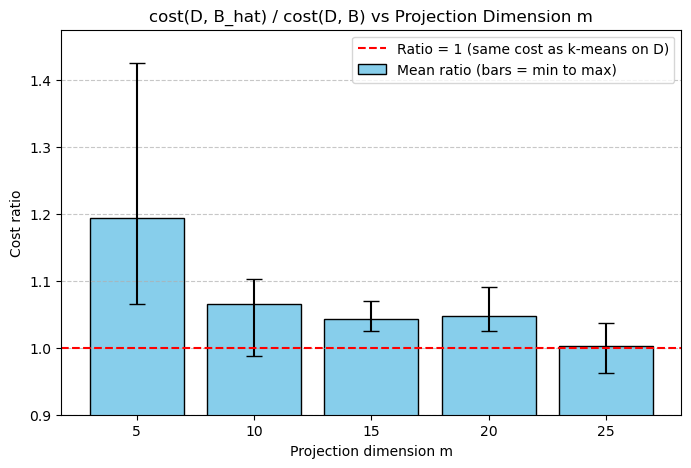

In [16]:
# Error bar lengths: how far the min is below the mean, and how far the max is above it
lower_err = summary_b['mean_B_hat'] - summary_b['min_B_hat']
upper_err = summary_b['max_B_hat'] - summary_b['mean_B_hat']

plt.figure(figsize=(8, 5))
plt.bar(summary_b.index.astype(str), summary_b['mean_B_hat'], color='skyblue', edgecolor='black',
        yerr=[lower_err, upper_err], capsize=6, label='Mean ratio (bars = min to max)')
plt.axhline(y=1, color='red', linestyle='--', label='Ratio = 1 (same cost as k-means on D)')
plt.title("cost(D, B_hat) / cost(D, B) vs Projection Dimension m")
plt.xlabel("Projection dimension m")
plt.ylabel("Cost ratio")
plt.ylim(0.9, summary_b['max_B_hat'].max() + 0.05)
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

### d) Running Time vs m

Time for k-means on full D (part a): 26.14 s

Average time (E + k-means on E) per m:
m
5     6.05
10    6.63
15    7.14
20    7.26
25    7.81
Name: Time (s), dtype: float64


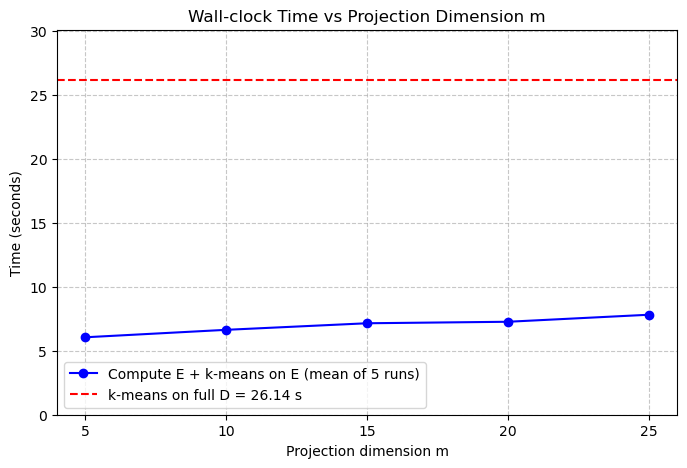

In [17]:
# Average time (compute E + k-means on E) over the 5 runs for each m
time_summary = results_b_df.groupby('m')['Time (s)'].mean()

print(f"Time for k-means on full D (part a): {time_D:.2f} s\n")
print("Average time (E + k-means on E) per m:")
print(time_summary.round(2))

plt.figure(figsize=(8, 5))
plt.plot(time_summary.index, time_summary.values, marker='o', linestyle='-', color='blue',
         label='Compute E + k-means on E (mean of 5 runs)')
plt.axhline(y=time_D, color='red', linestyle='--', label=f'k-means on full D = {time_D:.2f} s')
plt.title("Wall-clock Time vs Projection Dimension m")
plt.xlabel("Projection dimension m")
plt.ylabel("Time (seconds)")
plt.xticks(M_VALUES)
plt.ylim(0, time_D * 1.15)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()
plt.show()

### e) Distance and Clustering-Cost Distortion

In [18]:
# Restart the random generator so part (e) is reproducible on its own
rng = np.random.default_rng(SEED)

# Draw more candidate pairs than needed, because many rows of D are exact duplicates
n_candidates = 3 * N_PAIRS
i_cand = rng.integers(0, n, size=n_candidates)
l_cand = rng.integers(0, n, size=n_candidates)

# Keep only pairs whose rows are different (at least one feature differs)
different = np.any(D[i_cand] != D[l_cand], axis=1)
print(f"Candidate pairs with D_i != D_l: {different.sum()} out of {n_candidates}")

# Take the first 10^4 valid pairs, then use these SAME pairs for every m
pair_i = i_cand[different][:N_PAIRS]
pair_l = l_cand[different][:N_PAIRS]
print(f"Number of pairs selected: {len(pair_i)}")

# Differences D_i - D_l in float64 (reused for every m): E_i - E_l = A (D_i - D_l)
diff_D = D[pair_i].astype(np.float64) - D[pair_l].astype(np.float64)

# Squared distances in the original space (denominator of every ratio in e(i))
dist_D = (diff_D ** 2).sum(axis=1)
print(f"Smallest ||D_i - D_l||^2: {dist_D.min():.3e}")
print(f"Pairs with ||D_i - D_l||^2 below 1e-6: {(dist_D < 1e-6).sum()}")

Candidate pairs with D_i != D_l: 25238 out of 30000
Number of pairs selected: 10000
Smallest ||D_i - D_l||^2: 5.453e-13
Pairs with ||D_i - D_l||^2 below 1e-6: 611


In [19]:
# For each m: draw ONE A, then compute ||E_i - E_l||^2 / ||D_i - D_l||^2 for the same 10^4 pairs
pair_ratios = {}

for m in M_VALUES:
    A = draw_projection(m, d).astype(np.float64)

    # E_i - E_l = A (D_i - D_l), computed for all pairs at once
    diff_E = diff_D @ A.T                      # 10^4 x m
    dist_E = (diff_E ** 2).sum(axis=1)         # ||E_i - E_l||^2

    pair_ratios[m] = dist_E / dist_D

    print(f"m = {m:2d}: mean = {pair_ratios[m].mean():.4f}, std = {pair_ratios[m].std():.4f}, "
          f"min = {pair_ratios[m].min():.4f}, max = {pair_ratios[m].max():.4f}")

m =  5: mean = 1.1127, std = 0.6061, min = 0.0996, max = 4.8756
m = 10: mean = 0.7465, std = 0.4057, min = 0.1628, max = 2.2197
m = 15: mean = 0.8227, std = 0.2500, min = 0.2478, max = 2.1290
m = 20: mean = 0.8756, std = 0.2576, min = 0.3197, max = 1.8571
m = 25: mean = 0.9736, std = 0.1932, min = 0.3419, max = 2.2794


In [20]:
# Cost of the clusters C_D (from part a) measured in the original space D (same for every m, so compute once)
cost_D_CD = partition_cost(D, labels_D)
print(f"cost_D(C_D) = {cost_D_CD:.4f}\n")

# For each m: 20 independent A's, ratio cost_E(C_D) / cost_D(C_D) with the SAME clusters C_D
cluster_ratios = {}

for m in M_VALUES:
    ratios = []
    for draw in range(N_DRAWS_E):
        A = draw_projection(m, d)
        E = D @ A.T
        ratios.append(partition_cost(E, labels_D) / cost_D_CD)
    cluster_ratios[m] = np.array(ratios)

    print(f"m = {m:2d}: mean = {cluster_ratios[m].mean():.4f}, std = {cluster_ratios[m].std():.4f}, "
          f"min = {cluster_ratios[m].min():.4f}, max = {cluster_ratios[m].max():.4f}")

cost_D(C_D) = 54077.8796

m =  5: mean = 1.0003, std = 0.1788, min = 0.6787, max = 1.3085
m = 10: mean = 1.0558, std = 0.1021, min = 0.9007, max = 1.2707
m = 15: mean = 1.0233, std = 0.1002, min = 0.8105, max = 1.2372
m = 20: mean = 1.0218, std = 0.0997, min = 0.8312, max = 1.2500
m = 25: mean = 0.9736, std = 0.0735, min = 0.8073, max = 1.0901


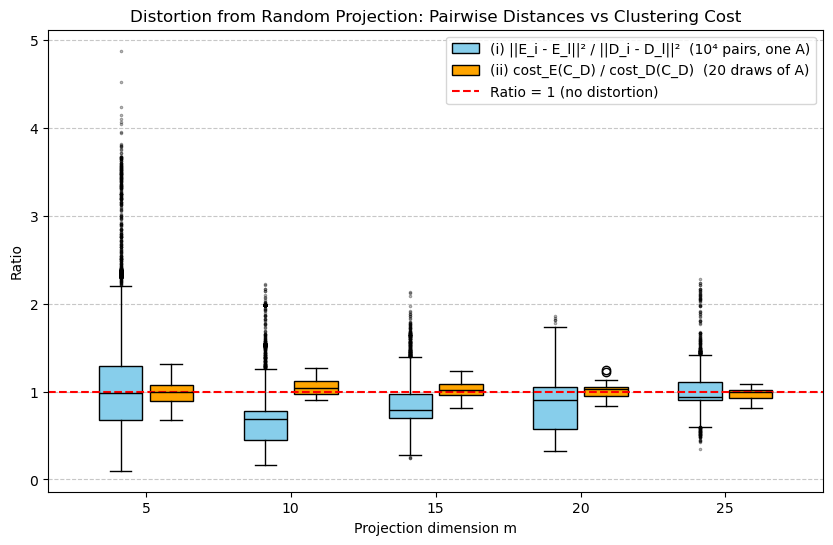

In [21]:
# Data for the box plots: one box per m for each type of ratio
pair_data = [pair_ratios[m] for m in M_VALUES]
cluster_data = [cluster_ratios[m] for m in M_VALUES]

# Positions: put the two boxes for each m side by side
x = np.arange(len(M_VALUES))
width = 0.35

plt.figure(figsize=(10, 6))
box_pairs = plt.boxplot(pair_data, positions=x - width / 2, widths=0.3, patch_artist=True,
                        boxprops=dict(facecolor='skyblue'), medianprops=dict(color='black'),
                        flierprops=dict(marker='.', markersize=3, alpha=0.4))
box_clusters = plt.boxplot(cluster_data, positions=x + width / 2, widths=0.3, patch_artist=True,
                           boxprops=dict(facecolor='orange'), medianprops=dict(color='black'))

plt.axhline(y=1, color='red', linestyle='--', label='Ratio = 1 (no distortion)')
plt.xticks(x, M_VALUES)
plt.title("Distortion from Random Projection: Pairwise Distances vs Clustering Cost")
plt.xlabel("Projection dimension m")
plt.ylabel("Ratio")
plt.legend([box_pairs['boxes'][0], box_clusters['boxes'][0], plt.gca().lines[-1]],
           ['(i) ||E_i - E_l||² / ||D_i - D_l||²  (10⁴ pairs, one A)',
            '(ii) cost_E(C_D) / cost_D(C_D)  (20 draws of A)',
            'Ratio = 1 (no distortion)'])
plt.grid(True, axis='y', linestyle='--', alpha=0.7)
plt.show()